In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/car_price_prediction

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/car_price_prediction


In [3]:
import shutil
from pathlib import Path

# Define the source path from your Google Drive
source_path = Path('kaggle.json')

# Define the destination path in the Colab system environment
kaggle_dir = Path.home() / '.kaggle'
dest_path = kaggle_dir / 'kaggle.json'

# Create the hidden .kaggle directory if it doesn't exist
kaggle_dir.mkdir(parents=True, exist_ok=True)

# Copy the json file from Drive to the hidden system directory
shutil.copy(source_path, dest_path)

# Set the required permissions (read/write for owner only) so Kaggle accepts it
dest_path.chmod(0o600)

print(f"Kaggle credentials successfully set up at: {dest_path}")

Kaggle credentials successfully set up at: /root/.kaggle/kaggle.json


In [4]:
import zipfile
from pathlib import Path

project_dir = Path('.')
data_dir = project_dir / 'data'
zip_path = project_dir / 'vehicle-dataset-from-cardekho.zip'


data_dir.mkdir(exist_ok=True)


if not zip_path.exists():
    !kaggle datasets download -d nehalbirla/vehicle-dataset-from-cardekho -p .

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(data_dir)

print(f"Dataset successfully extracted to: {data_dir.resolve()}")

Dataset successfully extracted to: /content/drive/MyDrive/car_price_prediction/data


In [5]:
import pandas as pd

# Join the directory path with the exact CSV file name
csv_path = data_dir / 'CAR DETAILS FROM CAR DEKHO.csv'

# Verify the file exists before loading
if csv_path.exists():
    car_df= pd.read_csv(csv_path)

    # Display the first 5 rows to confirm it loaded correctly
    display(car_df.head())
else:
    print(f"Error: Could not find the dataset at {csv_path}")

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [6]:
car_df.shape

(4340, 8)

In [7]:
car_df.describe(include='all')

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
count,4340,4340.000000,4.340000e+03,4340.000000,4340,4340,4340,4340
unique,1491,NaN,NaN,NaN,5,3,2,5
top,Maruti Swift Dzire VDI,NaN,NaN,NaN,Diesel,Individual,Manual,First Owner
freq,69,NaN,NaN,NaN,2153,3244,3892,2832
mean,NaN,2013.090783,5.041273e+05,66215.777419,NaN,NaN,NaN,NaN
std,NaN,4.215344,5.785487e+05,46644.102194,NaN,NaN,NaN,NaN
min,NaN,1992.000000,2.000000e+04,1.000000,NaN,NaN,NaN,NaN
25%,NaN,2011.000000,2.087498e+05,35000.000000,NaN,NaN,NaN,NaN
50%,NaN,2014.000000,3.500000e+05,60000.000000,NaN,NaN,NaN,NaN
75%,NaN,2016.000000,6.000000e+05,90000.000000,NaN,NaN,NaN,NaN


In [8]:
from utils import describe_with_whisker


In [9]:
describe_with_whisker(car_df)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
count,4340,4340.000000,4.340000e+03,4340.000000,4340,4340,4340,4340
unique,1491,NaN,NaN,NaN,5,3,2,5
top,Maruti Swift Dzire VDI,NaN,NaN,NaN,Diesel,Individual,Manual,First Owner
freq,69,NaN,NaN,NaN,2153,3244,3892,2832
mean,NaN,2013.090783,5.041273e+05,66215.777419,NaN,NaN,NaN,NaN
std,NaN,4.215344,5.785487e+05,46644.102194,NaN,NaN,NaN,NaN
min,NaN,1992.000000,2.000000e+04,1.000000,NaN,NaN,NaN,NaN
25%,NaN,2011.000000,2.087498e+05,35000.000000,NaN,NaN,NaN,NaN
50%,NaN,2014.000000,3.500000e+05,60000.000000,NaN,NaN,NaN,NaN
75%,NaN,2016.000000,6.000000e+05,90000.000000,NaN,NaN,NaN,NaN


In [10]:
car_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [11]:
car_df.duplicated().sum()

np.int64(763)

In [12]:
dupl_df=car_df[car_df.duplicated(keep=False)]
sort=dupl_df.sort_values(by=list(dupl_df.columns))
sort.head(1500)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
3912,Ambassador CLASSIC 1500 DSL AC,2005,120000,50000,Diesel,Individual,Manual,Second Owner
4016,Ambassador CLASSIC 1500 DSL AC,2005,120000,50000,Diesel,Individual,Manual,Second Owner
99,Audi A4 2.0 TDI 177 Bhp Premium Plus,2013,1150000,53000,Diesel,Dealer,Automatic,First Owner
2578,Audi A4 2.0 TDI 177 Bhp Premium Plus,2013,1150000,53000,Diesel,Dealer,Automatic,First Owner
554,Audi A4 3.0 TDI Quattro,2013,1580000,86000,Diesel,Dealer,Automatic,First Owner
...,...,...,...,...,...,...,...,...
2936,Volkswagen Vento 1.5 TDI Highline Plus AT,2017,890000,40219,Diesel,Dealer,Automatic,First Owner
1628,Volkswagen Vento Diesel Comfortline,2012,215000,97000,Diesel,Individual,Manual,First Owner
3052,Volkswagen Vento Diesel Comfortline,2012,215000,97000,Diesel,Individual,Manual,First Owner
478,Volkswagen Vento Diesel Highline,2011,300000,65000,Diesel,Individual,Manual,Second Owner


## i Will Remove Duplicated row

In [13]:
# Keep the first occurrence of each duplicated row and explicitly copy to prevent warning
clean_car_df = car_df.drop_duplicates(keep='first').copy()

print(f"Original dataset shape: {car_df.shape}")
print(f"Cleaned dataset shape: {clean_car_df.shape}")
print(f"Removed {car_df.shape[0] - clean_car_df.shape[0]} duplicate rows.")

Original dataset shape: (4340, 8)
Cleaned dataset shape: (3577, 8)
Removed 763 duplicate rows.


In [14]:
clean_car_df.duplicated().sum()

np.int64(0)

In [15]:
clean_car_df.dtypes

,0
name,object
year,int64
selling_price,int64
km_driven,int64
fuel,object
seller_type,object
transmission,object
owner,object


In [16]:
numerical_cols = clean_car_df.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = clean_car_df.select_dtypes(include=['object']).columns

In [17]:
for cat in categorical_cols:
    print(f"Value counts for {cat}:")
    print(clean_car_df[cat].value_counts())
    print("\n")

Value counts for name:
name
Maruti Swift Dzire VDI        54
Maruti Alto 800 LXI           48
Maruti Alto LXi               42
Maruti Alto LX                30
Maruti Swift VDI BSIV         28
                              ..
Tata Indica V2 DLS BSII        1
Mahindra XUV500 W10 AWD        1
Toyota Fortuner 2.7 2WD AT     1
Fiat Punto EVO 1.3 Emotion     1
Nissan Terrano XE 85 PS        1
Name: count, Length: 1491, dtype: int64


Value counts for fuel:
fuel
Diesel      1800
Petrol      1717
CNG           37
LPG           22
Electric       1
Name: count, dtype: int64


Value counts for seller_type:
seller_type
Individual          2832
Dealer               712
Trustmark Dealer      33
Name: count, dtype: int64


Value counts for transmission:
transmission
Manual       3265
Automatic     312
Name: count, dtype: int64


Value counts for owner:
owner
First Owner             2218
Second Owner             978
Third Owner              289
Fourth & Above Owner      75
Test Drive Car            1

## No Space in Start or End and No Symbols

In [18]:
for cat in categorical_cols:
    print(f" {cat}:")
    print(clean_car_df[cat].unique())
    print("\n")

 name:
['Maruti 800 AC' 'Maruti Wagon R LXI Minor' 'Hyundai Verna 1.6 SX' ...
 'Mahindra Verito 1.5 D6 BSIII'
 'Toyota Innova 2.5 VX (Diesel) 8 Seater BS IV'
 'Hyundai i20 Magna 1.4 CRDi']


 fuel:
['Petrol' 'Diesel' 'CNG' 'LPG' 'Electric']


 seller_type:
['Individual' 'Dealer' 'Trustmark Dealer']


 transmission:
['Manual' 'Automatic']


 owner:
['First Owner' 'Second Owner' 'Fourth & Above Owner' 'Third Owner'
 'Test Drive Car']




### Feature Extraction from Name Column
We will extract three features from the `name` column:
1. **Brand**: The manufacturer.
2. **Model**: The model of the car.


In [19]:
# 1. Extract brand (first word) and the remaining text as initial model
clean_car_df[['brand', 'model']] = clean_car_df['name'].str.strip().str.split(pat=' ', n=1, expand=True)

# 2. Fix 'Land Rover' multi-word brand extraction
is_land_rover = clean_car_df['brand'] == 'Land'
clean_car_df.loc[is_land_rover, 'brand'] = 'Land Rover'
clean_car_df.loc[is_land_rover, 'model'] = clean_car_df.loc[is_land_rover, 'model'].str.replace('Rover ', '', regex=False)

# 3. Clean prefixes ('New', 'Elite') and standardize 'Class' (Mercedes) and 'Series' (BMW)
clean_car_df['model'] = (
    clean_car_df['model']
    .str.replace(r'^(New|Elite)\s+', '', regex=True, case=False)  # Remove leading 'New ' or 'Elite '
    .str.replace(r'\s+Class\b', '-Class', regex=True, case=False)  # Turn 'C Class' into 'C-Class'
    .str.replace(r'\s+Series\b', '-Series', regex=True, case=False)  # Turn '7 Series' into '7-Series'
    .str.replace(r'^Grand\s+i10\b', 'Grand-i10', regex=True, case=False)  # Keep 'Grand-i10' together
    .str.replace(r'^Wagon\s+R\b', 'Wagon-R', regex=True, case=False)  # Keep 'Wagon-R' together
)

# 4. Keep only the core model name (first word)
clean_car_df['model'] = clean_car_df['model'].str.split().str[0]

# Check unique values and verify BMW & Mercedes-Benz models
print(f"Total unique brands: {clean_car_df['brand'].nunique()}")
print(f"Total unique models: {clean_car_df['model'].nunique()}\n")

print("Extracted models preview:")
display(clean_car_df.loc[:, ['brand', 'model', 'name']])

Total unique brands: 29
Total unique models: 185

Extracted models preview:


,brand,model,name
0,Maruti,800,Maruti 800 AC
1,Maruti,Wagon-R,Maruti Wagon R LXI Minor
2,Hyundai,Verna,Hyundai Verna 1.6 SX
3,Datsun,RediGO,Datsun RediGO T Option
4,Honda,Amaze,Honda Amaze VX i-DTEC
...,...,...,...
4335,Hyundai,i20,Hyundai i20 Magna 1.4 CRDi (Diesel)
4336,Hyundai,i20,Hyundai i20 Magna 1.4 CRDi
4337,Maruti,800,Maruti 800 AC BSIII
4338,Hyundai,Creta,Hyundai Creta 1.6 CRDi SX Option


In [20]:
clean_car_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3577 entries, 0 to 4339
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           3577 non-null   object
 1   year           3577 non-null   int64 
 2   selling_price  3577 non-null   int64 
 3   km_driven      3577 non-null   int64 
 4   fuel           3577 non-null   object
 5   seller_type    3577 non-null   object
 6   transmission   3577 non-null   object
 7   owner          3577 non-null   object
 8   brand          3577 non-null   object
 9   model          3577 non-null   object
dtypes: int64(3), object(7)
memory usage: 307.4+ KB


In [21]:
# Combine 'CNG' and 'LPG' into 'Gas'
clean_car_df['fuel'] = clean_car_df['fuel'].replace(['CNG', 'LPG'], 'Gas')

# Remove rows with 'Electric' fuel type
clean_car_df = clean_car_df[clean_car_df['fuel'] != 'Electric']

# Verify the updated fuel column counts
print("Updated fuel column value counts:")
print(clean_car_df['fuel'].value_counts())
print(f"New dataset shape: {clean_car_df.shape}")

Updated fuel column value counts:
fuel
Diesel    1800
Petrol    1717
Gas         59
Name: count, dtype: int64
New dataset shape: (3576, 10)


In [22]:
from datetime import datetime

# Get the current year dynamically (2026)
current_year = datetime.now().year
# Calculate the gap between the current year (2026) and the dataset's max year (2020)
max_dataset_year = clean_car_df['year'].max()
year_shift = current_year - max_dataset_year


# Create 'car_age' feature based on the updated year
clean_car_df['car_age'] = current_year - clean_car_df['year']

# Verify the updated year range and car_age distribution
print(f"Dataset shifted by: +{year_shift} years")
print(f"Car age range: {clean_car_df['car_age'].min()} to {clean_car_df['car_age'].max()} years\n")

display(clean_car_df[['brand', 'model', 'year', 'car_age', 'selling_price']].head(10))

Dataset shifted by: +6 years
Car age range: 6 to 34 years



,brand,model,year,car_age,selling_price
0,Maruti,800,2007,19,60000
1,Maruti,Wagon-R,2007,19,135000
2,Hyundai,Verna,2012,14,600000
3,Datsun,RediGO,2017,9,250000
4,Honda,Amaze,2014,12,450000
5,Maruti,Alto,2007,19,140000
6,Hyundai,Xcent,2016,10,550000
7,Tata,Indigo,2014,12,240000
8,Hyundai,Creta,2015,11,850000
9,Maruti,Celerio,2017,9,365000


In [23]:
clean_car_df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'brand', 'model', 'car_age'],
      dtype='object')

In [24]:
numerical_cols = clean_car_df.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = clean_car_df.select_dtypes(include=['object']).columns

In [25]:
clean_car_df.dtypes

,0
name,object
year,int64
selling_price,int64
km_driven,int64
fuel,object
seller_type,object
transmission,object
owner,object
brand,object
model,object


In [26]:
from utils import optimize_memory
optimize_memory(clean_car_df)

Memory decreased from 1.54 MB to 0.25 MB (83.7% reduction).


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,brand,model,car_age
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner,Maruti,800,19
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner,Maruti,Wagon-R,19
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner,Hyundai,Verna,14
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner,Datsun,RediGO,9
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner,Honda,Amaze,12
...,...,...,...,...,...,...,...,...,...,...,...
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,409999,80000,Diesel,Individual,Manual,Second Owner,Hyundai,i20,12
4336,Hyundai i20 Magna 1.4 CRDi,2014,409999,80000,Diesel,Individual,Manual,Second Owner,Hyundai,i20,12
4337,Maruti 800 AC BSIII,2009,110000,83000,Petrol,Individual,Manual,Second Owner,Maruti,800,17
4338,Hyundai Creta 1.6 CRDi SX Option,2016,865000,90000,Diesel,Individual,Manual,First Owner,Hyundai,Creta,10


In [27]:
clean_car_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3576 entries, 0 to 4339
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   name           3576 non-null   category
 1   year           3576 non-null   int16   
 2   selling_price  3576 non-null   int32   
 3   km_driven      3576 non-null   int32   
 4   fuel           3576 non-null   category
 5   seller_type    3576 non-null   category
 6   transmission   3576 non-null   category
 7   owner          3576 non-null   category
 8   brand          3576 non-null   category
 9   model          3576 non-null   category
 10  car_age        3576 non-null   int8    
dtypes: category(7), int16(1), int32(2), int8(1)
memory usage: 149.1 KB


In [28]:
describe_with_whisker(clean_car_df)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,brand,model,car_age
count,3576,3576.000000,3.576000e+03,3576.000000,3576,3576,3576,3576,3576,3576,3576.000000
unique,1490,NaN,NaN,NaN,3,3,2,5,29,185,NaN
top,Maruti Swift Dzire VDI,NaN,NaN,NaN,Diesel,Individual,Manual,First Owner,Maruti,Swift,NaN
freq,54,NaN,NaN,NaN,1800,2832,3265,2218,1072,270,NaN
mean,NaN,2012.964485,4.739584e+05,69252.573266,NaN,NaN,NaN,NaN,NaN,NaN,13.035515
std,NaN,4.250759,5.093657e+05,47586.439537,NaN,NaN,NaN,NaN,NaN,NaN,4.250759
min,NaN,1992.000000,2.000000e+04,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,6.000000
25%,NaN,2010.000000,2.000000e+05,36000.000000,NaN,NaN,NaN,NaN,NaN,NaN,10.000000
50%,NaN,2013.000000,3.500000e+05,60000.000000,NaN,NaN,NaN,NaN,NaN,NaN,13.000000
75%,NaN,2016.000000,6.000000e+05,90000.000000,NaN,NaN,NaN,NaN,NaN,NaN,16.000000


## Univariate Analysis

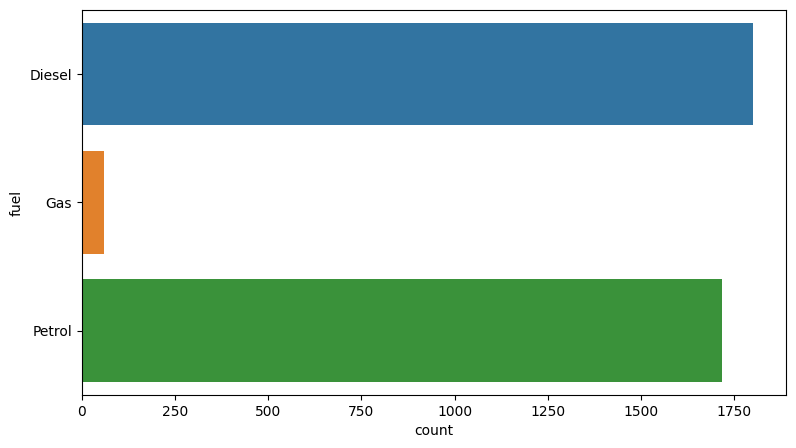

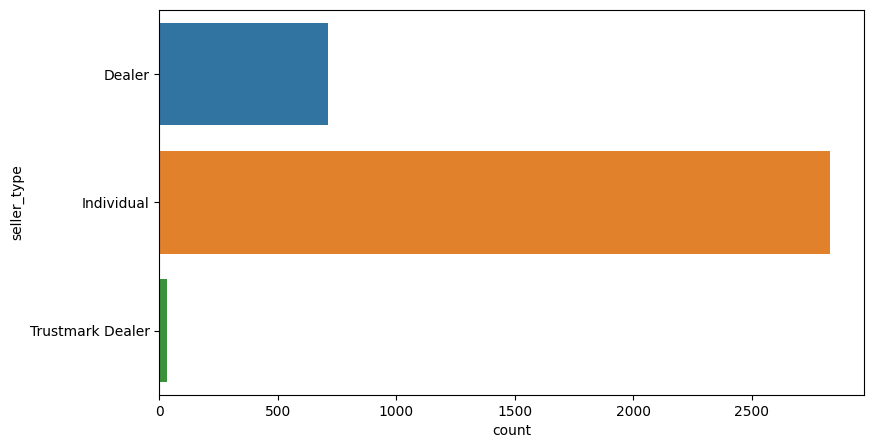

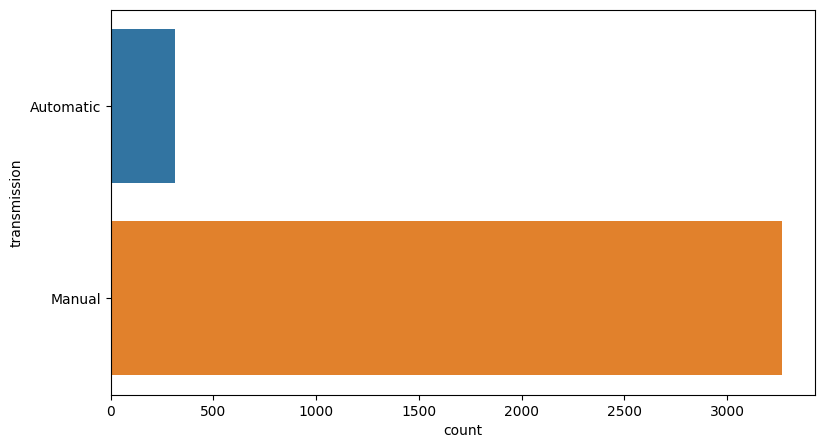

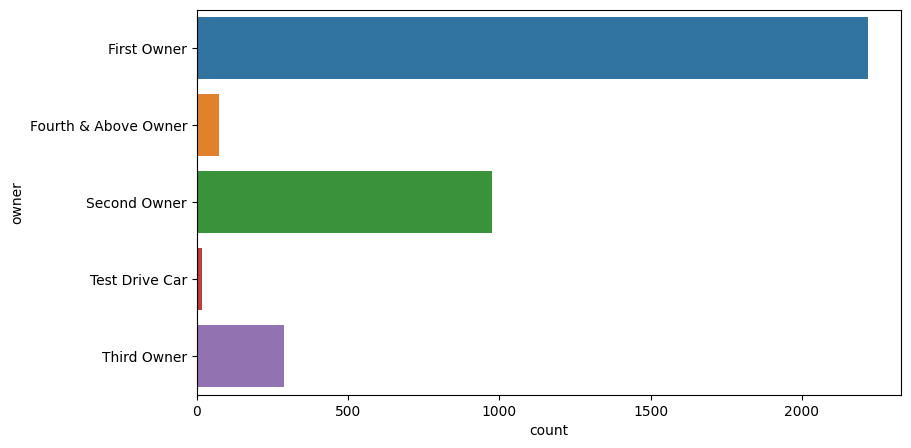

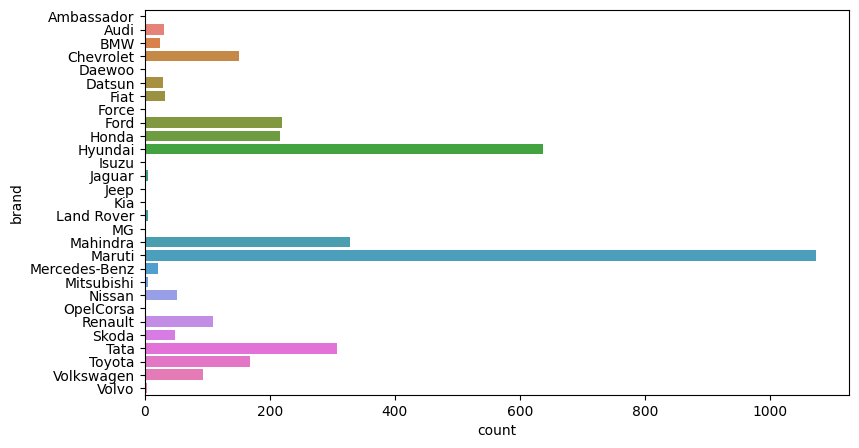

In [29]:
for cat in categorical_cols:
  if cat not in ['name','model']:
    plt.figure(figsize=(20,5))
    plt.subplot(1,2,1)
    sns.countplot(data=clean_car_df, y=cat,hue=cat )
    plt.show()

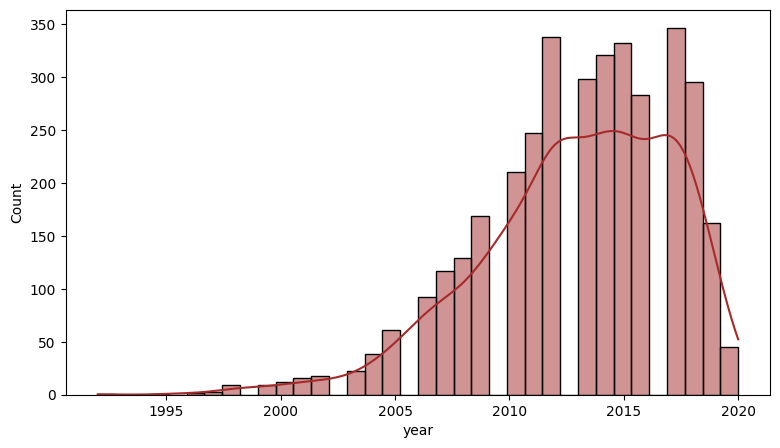

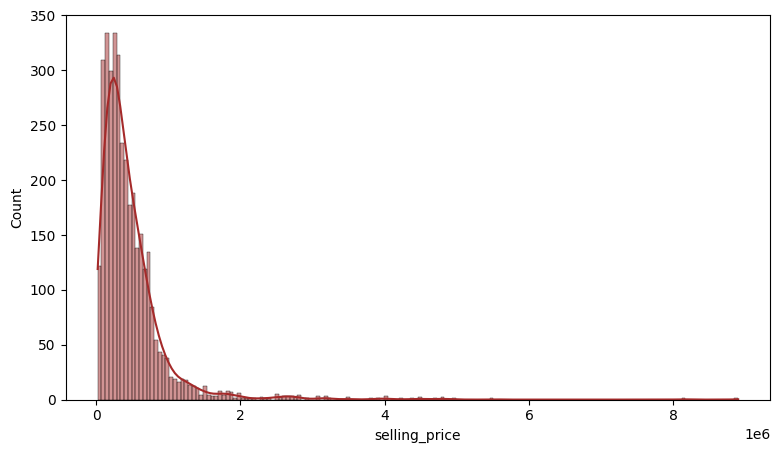

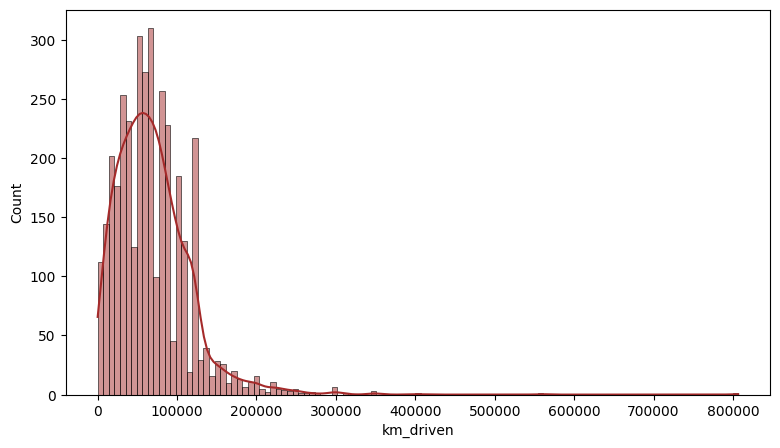

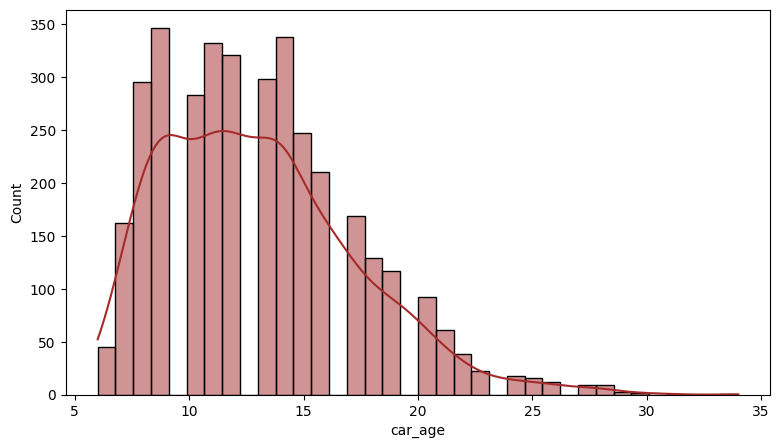

In [30]:
for num_col in numerical_cols:
    plt.figure(figsize=(20,5))
    plt.subplot(1,2,1)
    sns.histplot(data=clean_car_df, x=num_col,kde=True,color='brown')
    plt.show()

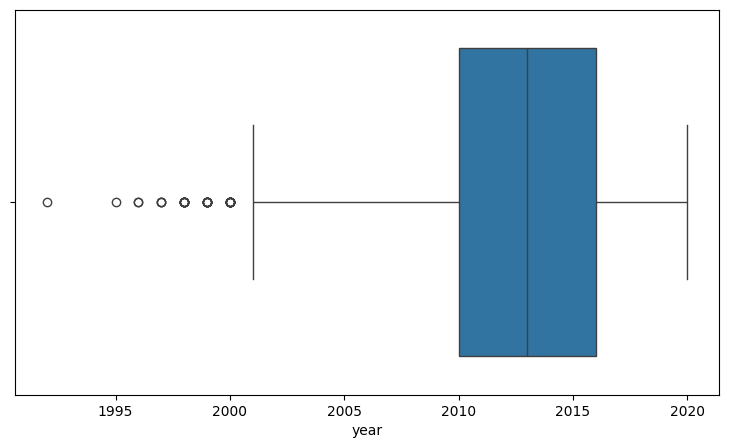

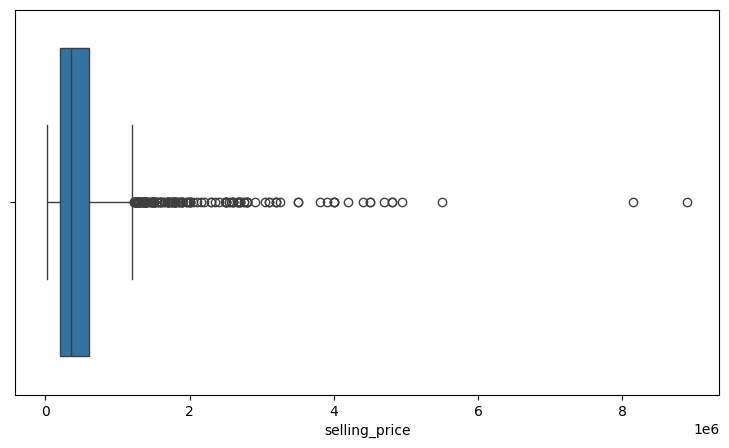

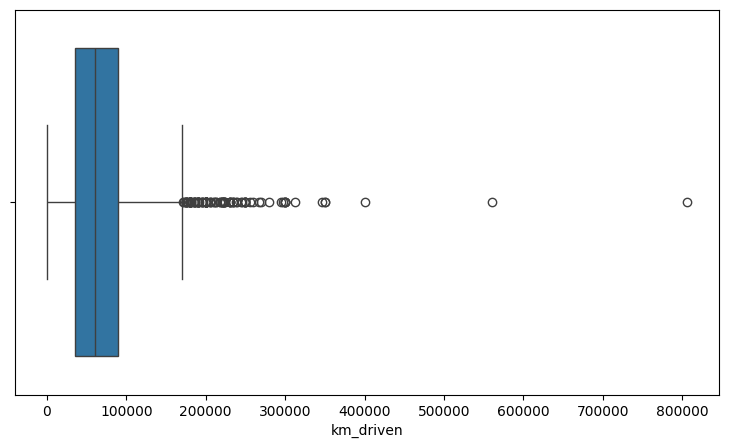

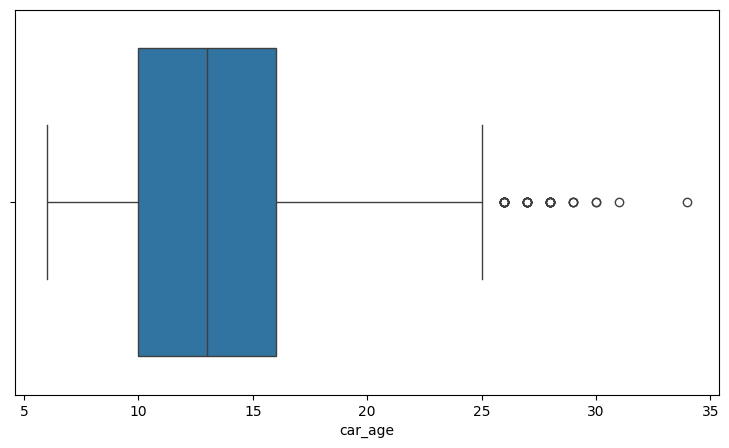

In [31]:
for num_col in numerical_cols:
  fig = plt.figure(figsize=(20, 5))
  plt.subplot(1, 2, 1)
  sns.boxplot(data=clean_car_df, x=num_col)
  plt.show()

## CHECK THE Outliers

In [32]:
clean_car_df[clean_car_df['year'] < clean_car_df['year'].quantile(0.01)]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,brand,model,car_age
61,Mahindra Jeep CL 500 MDI,1996,250000,35000,Diesel,Individual,Manual,Second Owner,Mahindra,Jeep,30
137,Maruti 800 Std,1998,40000,40000,Petrol,Individual,Manual,Fourth & Above Owner,Maruti,800,28
391,Hyundai Santro GLS I - Euro I,1999,50000,120000,Petrol,Individual,Manual,Second Owner,Hyundai,Santro,27
631,Maruti Gypsy E MG410W ST,1995,95000,100000,Petrol,Individual,Manual,Second Owner,Maruti,Gypsy,31
850,Maruti Zen LXI,1999,85000,70000,Petrol,Individual,Manual,Second Owner,Maruti,Zen,27
1126,Maruti Esteem VX,1999,60000,35000,Petrol,Individual,Manual,Second Owner,Maruti,Esteem,27
1579,Mahindra Jeep Classic,1999,170000,2020,Diesel,Individual,Manual,Second Owner,Mahindra,Jeep,27
1669,Mahindra Jeep CL 500 MDI,1997,150000,120000,Diesel,Individual,Manual,Third Owner,Mahindra,Jeep,29
1699,Maruti Omni 5 Str STD LPG,1998,50000,35000,Gas,Individual,Manual,Second Owner,Maruti,Omni,28
1943,Maruti Zen LXI,1998,69000,70000,Petrol,Individual,Manual,Second Owner,Maruti,Zen,28


In [33]:
clean_car_df[clean_car_df['selling_price'] > clean_car_df['selling_price'].quantile(0.99)].loc[:, ['brand', 'model', 'selling_price']]

,brand,model,selling_price
89,Mercedes-Benz,S-Class,8150000
96,Audi,A8,2800000
101,Mercedes-Benz,E-Class,4500000
102,BMW,X1,2750000
204,BMW,5-Series,2900000
527,Toyota,Fortuner,2750000
539,Mercedes-Benz,GL-Class,4400000
553,Mercedes-Benz,C-Class,3800000
555,BMW,X5,4950000
731,Land Rover,Discovery,4000000


In [34]:
clean_car_df[clean_car_df['km_driven'] > clean_car_df['km_driven'].quantile(0.99)].loc[:, ['brand', 'model', 'car_age','km_driven']]

,brand,model,car_age,km_driven
69,Chevrolet,Tavera,16,350000
70,Toyota,Corolla,15,230000
197,Mahindra,Xylo,17,230000
525,Maruti,SX4,10,560000
1101,Tata,Indica,20,300000
1243,Maruti,Swift,17,806599
1253,Toyota,Corolla,12,234000
1414,Skoda,Superb,15,235000
1426,Mahindra,Scorpio,22,223660
1659,Toyota,Innova,20,300000


In [35]:
clean_car_df[clean_car_df['car_age'] > clean_car_df['car_age'].quantile(0.99)]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,brand,model,car_age
61,Mahindra Jeep CL 500 MDI,1996,250000,35000,Diesel,Individual,Manual,Second Owner,Mahindra,Jeep,30
137,Maruti 800 Std,1998,40000,40000,Petrol,Individual,Manual,Fourth & Above Owner,Maruti,800,28
391,Hyundai Santro GLS I - Euro I,1999,50000,120000,Petrol,Individual,Manual,Second Owner,Hyundai,Santro,27
631,Maruti Gypsy E MG410W ST,1995,95000,100000,Petrol,Individual,Manual,Second Owner,Maruti,Gypsy,31
850,Maruti Zen LXI,1999,85000,70000,Petrol,Individual,Manual,Second Owner,Maruti,Zen,27
1126,Maruti Esteem VX,1999,60000,35000,Petrol,Individual,Manual,Second Owner,Maruti,Esteem,27
1579,Mahindra Jeep Classic,1999,170000,2020,Diesel,Individual,Manual,Second Owner,Mahindra,Jeep,27
1669,Mahindra Jeep CL 500 MDI,1997,150000,120000,Diesel,Individual,Manual,Third Owner,Mahindra,Jeep,29
1699,Maruti Omni 5 Str STD LPG,1998,50000,35000,Gas,Individual,Manual,Second Owner,Maruti,Omni,28
1943,Maruti Zen LXI,1998,69000,70000,Petrol,Individual,Manual,Second Owner,Maruti,Zen,28


In [36]:
describe_with_whisker(clean_car_df)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,brand,model,car_age
count,3576,3576.000000,3.576000e+03,3576.000000,3576,3576,3576,3576,3576,3576,3576.000000
unique,1490,NaN,NaN,NaN,3,3,2,5,29,185,NaN
top,Maruti Swift Dzire VDI,NaN,NaN,NaN,Diesel,Individual,Manual,First Owner,Maruti,Swift,NaN
freq,54,NaN,NaN,NaN,1800,2832,3265,2218,1072,270,NaN
mean,NaN,2012.964485,4.739584e+05,69252.573266,NaN,NaN,NaN,NaN,NaN,NaN,13.035515
std,NaN,4.250759,5.093657e+05,47586.439537,NaN,NaN,NaN,NaN,NaN,NaN,4.250759
min,NaN,1992.000000,2.000000e+04,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,6.000000
25%,NaN,2010.000000,2.000000e+05,36000.000000,NaN,NaN,NaN,NaN,NaN,NaN,10.000000
50%,NaN,2013.000000,3.500000e+05,60000.000000,NaN,NaN,NaN,NaN,NaN,NaN,13.000000
75%,NaN,2016.000000,6.000000e+05,90000.000000,NaN,NaN,NaN,NaN,NaN,NaN,16.000000


### Outlier Analysis Observation

Upon checking the data points beyond the standard IQR whiskers, we conclude that these are **normal outliers**:
* **Selling Price**: The high price outliers (up to 89 Lakhs) consist exclusively of luxury vehicles from brands such as Audi, BMW, Mercedes-Benz, Land Rover, and Volvo. This is completely representative of real market variations.
* **Kilometers Driven**: Vehicles with extreme mileage (up to 800k km) are older models from reliable, utility-focused brands like Toyota (Innova), Mahindra (Scorpio/Bolero), and Maruti (Swift), which are known to be used extensively over long periods.
* **Car Age**: Older cars (up to 34 years old) like Maruti 800, Gypsy, and Mahindra Jeeps are vintage and classic models that are naturally still present in the market.

**Decision**: Since these outliers are authentic, logical, and represent true variance in the automotive market, we will **keep them** in the dataset so our predictive models can learn to generalize well across both standard budget cars and high-end luxury/workhorse vehicles.

### Observations from Univariate Analysis

#### 1. Numerical Features
* **Selling Price (`selling_price`)**:
  * Extremely right-skewed. Most used cars are concentrated in the lower price bracket (typically below 5 Lakhs INR).
  * There are clear high-end outliers reaching up to 89 Lakhs INR (e.g., luxury brands like Mercedes-Benz S-Class, Audi, BMW, and Land Rover).
* **Kilometers Driven (`km_driven`)**:
  * Moderately right-skewed with a peak around 50,000 to 80,000 km.
  * Significant outliers exist on the high end, including a few vehicles with over 300,000 km (and one extreme case at 806,599 km).
* **Car Age (`car_age`)**:
  * Most cars in the dataset are between 10 to 16 years old (dating back to their 2010–2016 production range prior to the 2026 current year adjustment).
  * The distribution is relatively normal but slightly right-skewed with vintage/older outliers reaching up to 34 years.

#### 2. Categorical Features
* **Fuel Type (`fuel`)**:
  * Diesel and Petrol cars dominate the dataset in almost equal proportions.
  * Gas (CNG/LPG combined) represents a very minor share of the market, and Electric was removed due to having only 1 entry.
* **Seller Type (`seller_type`)**:
  * The overwhelming majority of cars are listed by **Individual** sellers.
  * Dealers make up a smaller portion, and Trustmark Dealers are extremely rare.
* **Transmission**:
  * **Manual** transmission cars vastly outnumber **Automatic** transmission cars, indicating a strong preference or availability of manual cars in this market.
* **Owner**:
  * Most vehicles are listed by their **First Owner**, followed by **Second Owner**.
  * Third, Fourth & Above, and Test Drive Cars represent only a small fraction of the dataset.

## Bivariate analysis

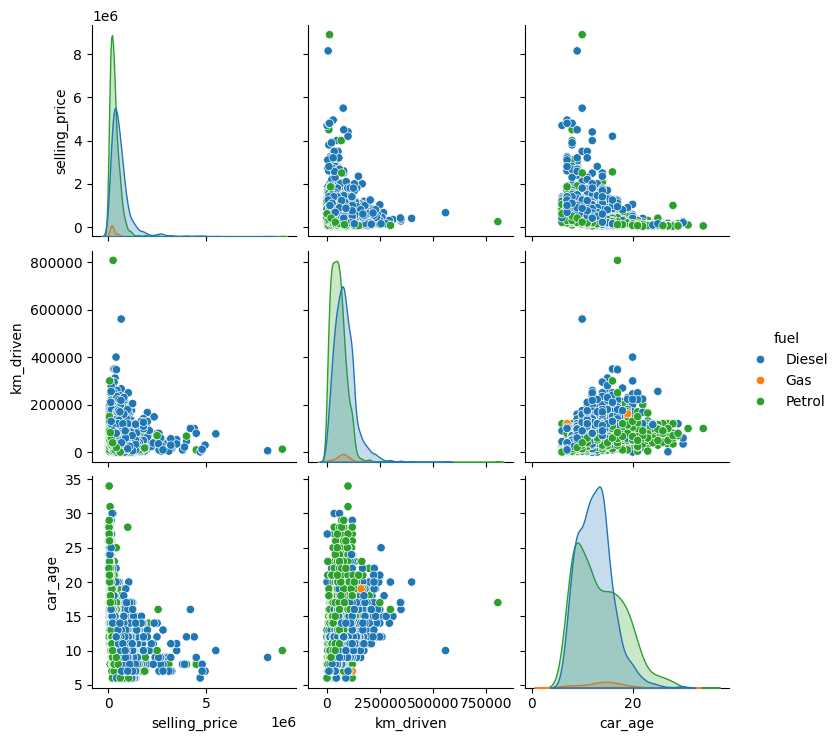

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt


sns.pairplot(clean_car_df[['selling_price', 'km_driven', 'car_age', 'fuel']], hue='fuel', diag_kind='kde')
plt.show()

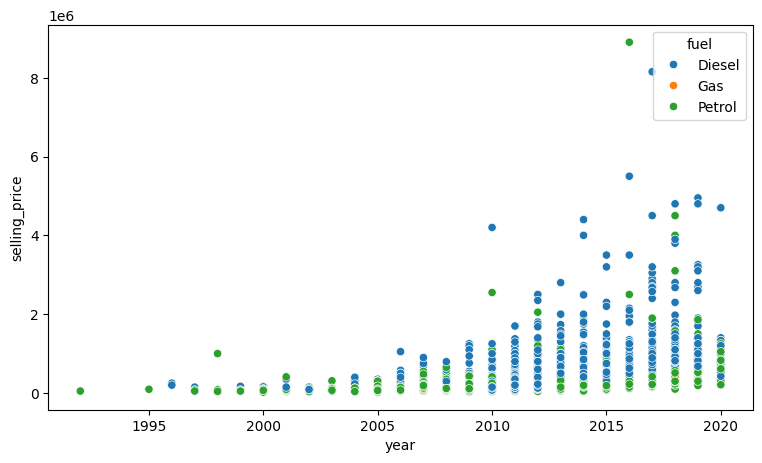

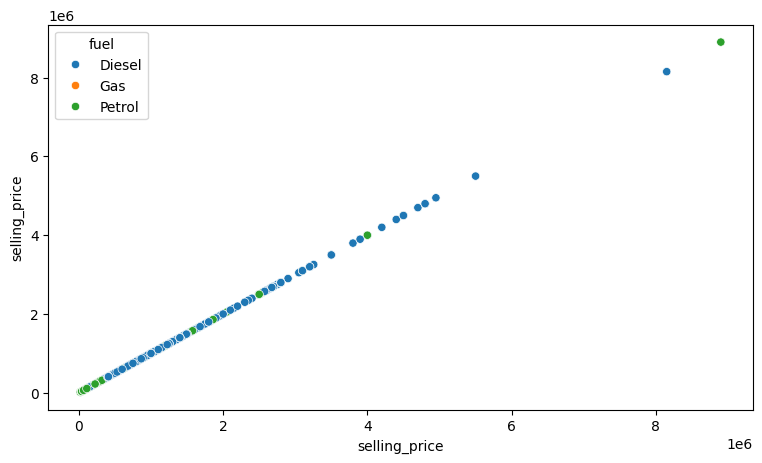

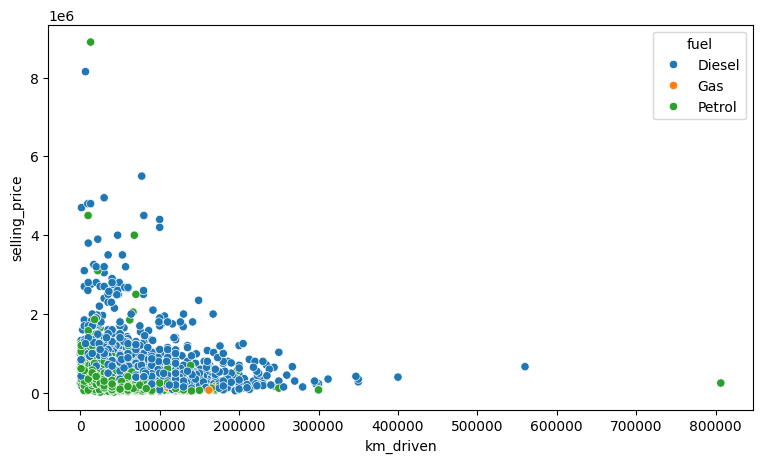

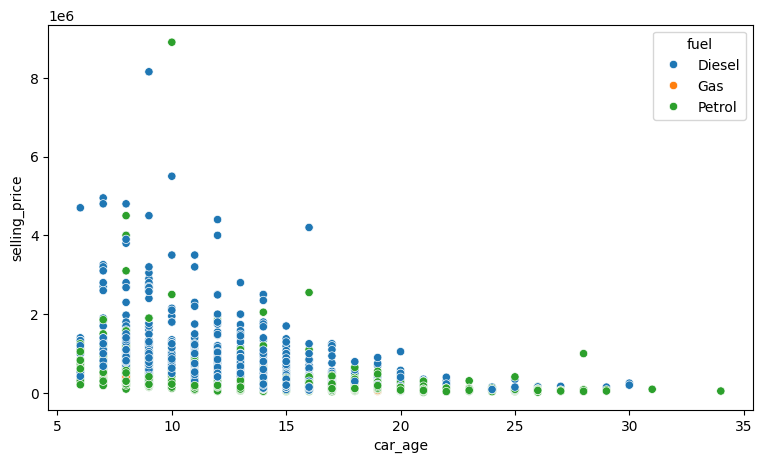

In [38]:
for num_col in numerical_cols:
  plt.figure(figsize=(20,5))
  plt.subplot(1,2,1)
  sns.scatterplot(data=clean_car_df, x=num_col,y='selling_price',hue='fuel')
  plt.show()

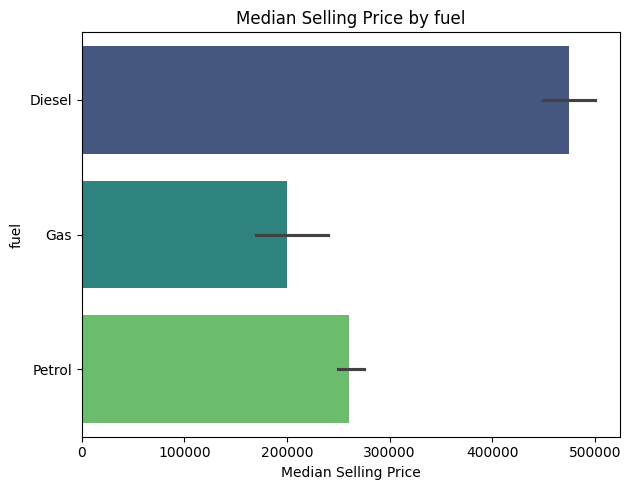

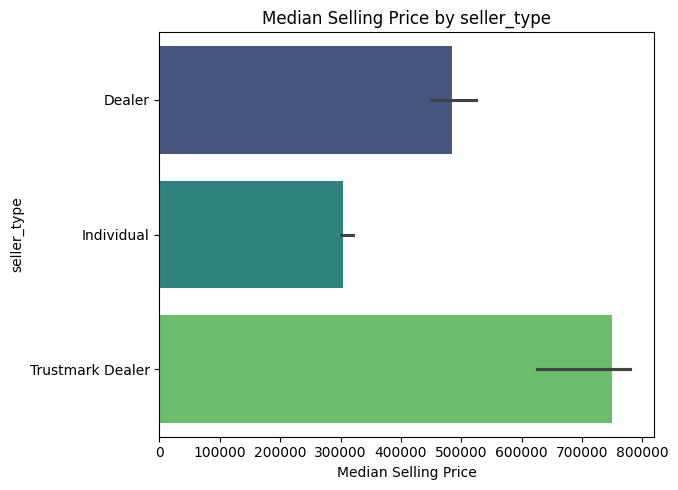

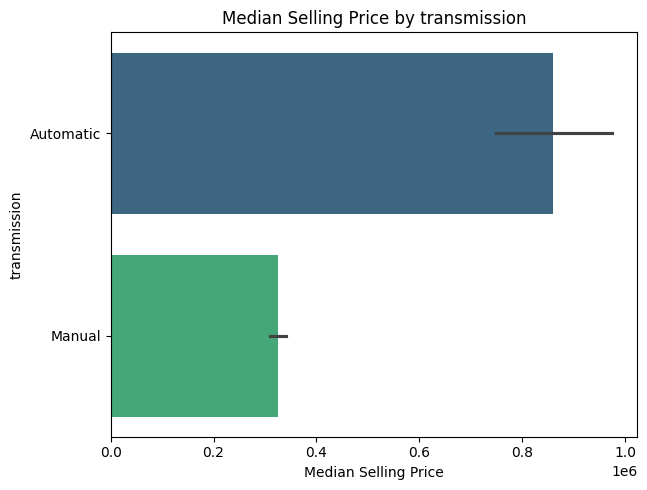

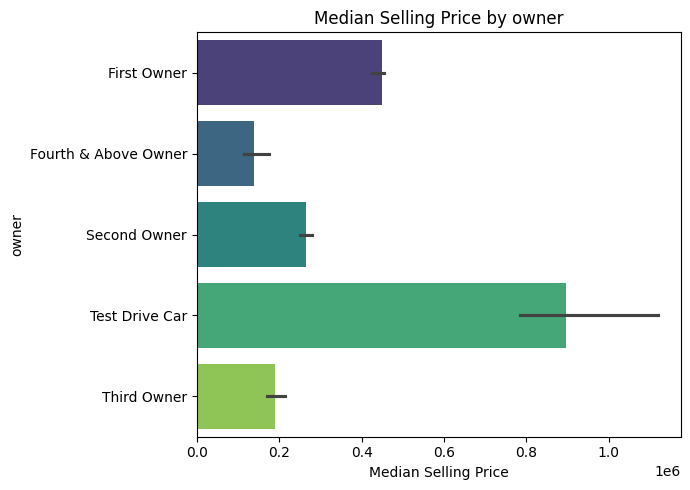

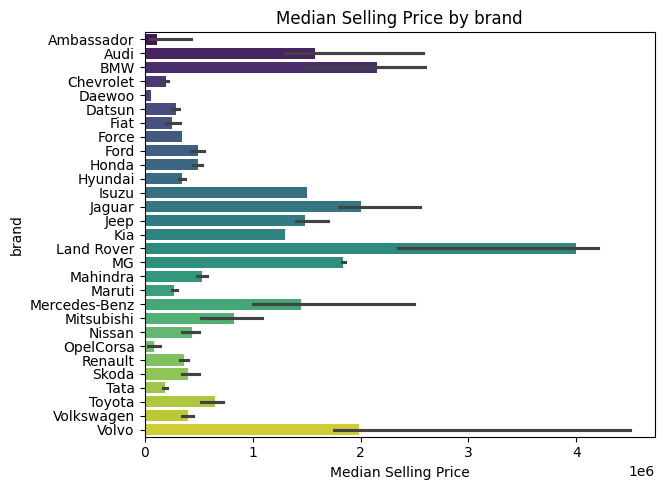

In [39]:

for cat in categorical_cols:
    if cat not in ['name', 'model']:
        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        sns.barplot(
            data=clean_car_df,
            y=cat,
            x='selling_price',
            estimator='median',
            palette='viridis',
            hue=cat
        )

        plt.title(f'Median Selling Price by {cat}')
        plt.xlabel('Median Selling Price')
        plt.ylabel(cat)
        plt.tight_layout()


In [40]:
clean_car_df[numerical_cols].corr()

,year,selling_price,km_driven,car_age
year,1.000000,0.424278,-0.417718,-1.000000
selling_price,0.424278,1.000000,-0.187376,-0.424278
km_driven,-0.417718,-0.187376,1.000000,0.417718
car_age,-1.000000,-0.424278,0.417718,1.000000


<Axes: >

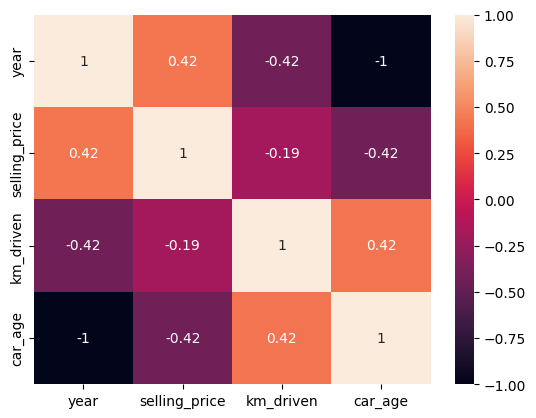

In [41]:
sns.heatmap(clean_car_df[numerical_cols].corr(),annot=True)

In [42]:
print(categorical_cols)

Index(['name', 'fuel', 'seller_type', 'transmission', 'owner', 'brand',
       'model'],
      dtype='object')


In [43]:
import pandas as pd

# Create the pivot table with transmission, seller_type, and owner as columns
price_pivot = pd.pivot_table(
    data=clean_car_df,
    values='selling_price',
    index='brand',
    columns=['transmission', 'seller_type','owner'],
    aggfunc='median',
    observed=False
)

# Sort by using 'First Owner' (with a space) instead of 'First_Owner'
price_pivot = price_pivot.sort_values(by=('Automatic', 'Dealer','First Owner'), ascending=False)
print("Median Selling Price by Brand and Transmission (Sorted by Automatic Dealer prices for First Owners):")
display(price_pivot)

Median Selling Price by Brand and Transmission (Sorted by Automatic Dealer prices for First Owners):


transmission    Automatic                                                      \
seller_type        Dealer                                          Individual   
owner         First Owner Second Owner Test Drive Car Third Owner First Owner   
brand                                                                           
Land Rover      3850000.0          NaN            NaN         NaN   4000000.0   
BMW             2075000.0    1550000.0            NaN         NaN   2675000.0   
Volvo           1975000.0          NaN            NaN   1750000.0   3250000.0   
Jaguar          1964999.0    2050000.0            NaN         NaN         NaN   
MG              1860000.0          NaN            NaN         NaN         NaN   
Ford            1800000.0     475000.0            NaN         NaN   2700000.0   
Toyota          1775000.0    1725000.0            NaN         NaN   1900000.0   
Audi            1750000.0    1360000.0            NaN   1250000.0   2900000.0   
Mercedes-Benz   1438000.0    1375000.0            NaN         NaN   2245000.0   
Mahindra        1150000.0          NaN            NaN         NaN   1400000.0   
Volkswagen       729500.0     850000.0            NaN         NaN    680000.0   
Chevrolet        720000.0          NaN            NaN         NaN    650000.0   
Honda            652500.0     434999.0      1165000.0         NaN    400000.0   
Skoda            599000.0     599000.0            NaN         NaN    800000.0   
Tata             525000.0          NaN            NaN         NaN   1200000.0   
Hyundai          510000.0     500000.0            NaN         NaN    720000.0   
Maruti           420000.0     338000.0            NaN         NaN    550000.0   
Renault          350000.0          NaN            NaN         NaN    327500.0   
Datsun           290000.0          NaN            NaN         NaN    300000.0   
Ambassador            NaN          NaN            NaN         NaN         NaN   
Daewoo                NaN          NaN            NaN         NaN         NaN   
Fiat                  NaN          NaN            NaN         NaN         NaN   
Force                 NaN          NaN            NaN         NaN         NaN   
Isuzu                 NaN          NaN            NaN         NaN         NaN   
Jeep                  NaN          NaN            NaN         NaN         NaN   
Kia                   NaN          NaN            NaN         NaN   1300000.0   
Mitsubishi            NaN          NaN            NaN         NaN    525000.0   
Nissan                NaN          NaN            NaN         NaN         NaN   
OpelCorsa             NaN          NaN            NaN         NaN         NaN   

transmission                                                                  \
seller_type                                                 Trustmark Dealer   
owner         Fourth & Above Owner Second Owner Third Owner      First Owner   
brand                                                                          
Land Rover                     NaN    2349000.0         NaN              NaN   
BMW                            NaN     750000.0   1200000.0              NaN   
Volvo                          NaN          NaN         NaN              NaN   
Jaguar                         NaN    2000000.0         NaN              NaN   
MG                             NaN          NaN         NaN              NaN   
Ford                      400000.0    1000000.0         NaN         750000.0   
Toyota                         NaN    1297500.0    350000.0        2597500.0   
Audi                           NaN    1350000.0   1200000.0              NaN   
Mercedes-Benz                  NaN    1800000.0         NaN              NaN   
Mahindra                       NaN     730000.0    275000.0              NaN   
Volkswagen                     NaN     285000.0    300000.0              NaN   
Chevrolet                      NaN          NaN    359000.0              NaN   
Honda                          NaN     285000.

### Observations from Bivariate Analysis

#### 1. Numerical Relationships with Selling Price
* **Car Age & Selling Price (Strong Negative Correlation: ~ -0.42)**:
  * Newer cars command significantly higher prices. As `car_age` increases, the selling price declines steeply, displaying a classic exponential depreciation curve.
* **Kilometers Driven & Selling Price (Weak Negative Correlation: ~ -0.19)**:
  * There is a general downward trend in price as mileage increases. However, the correlation is weaker than age, indicating that a well-maintained or premium car with higher mileage can still hold its value better than an older car with low mileage.
* **Car Age & Kilometers Driven (Moderate Positive Correlation: ~ 0.42)**:
  * As expected, older cars tend to accumulate higher mileage, which acts as a secondary factor in depreciation.

#### 2. Categorical Influences on Selling Price
* **Transmission Premium**:
  * **Automatic** transmission cars command a major premium over **Manual** transmission cars. Across almost all brands (especially visible in the sorted pivot table), automatic variants have substantially higher median selling prices.
* **Fuel Type Impact**:
  * **Diesel** cars generally have higher median selling prices compared to **Petrol** and **Gas** cars. This is often driven by SUV/utility models (like Toyota Innova and Mahindra Scorpio) which are prominently diesel-powered and retain high resale values.
* **Seller Type Impact**:
  * Vehicles sold by **Dealers** and **Trustmark Dealers** obtain higher median selling prices than those sold directly by **Individual** private sellers. This points to dealer markups, professional reconditioning, and warranty offers raising the market price.
* **Owner History Depreciation**:
  * There is a clear sequential price drop with ownership history. **First Owner** vehicles yield the highest median prices, followed by **Second Owner**, **Third Owner**, and **Fourth & Above Owner** vehicles, reflecting the perceived wear-and-tear of multiple handovers.

In [44]:
describe_with_whisker(clean_car_df)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,brand,model,car_age
count,3576,3576.000000,3.576000e+03,3576.000000,3576,3576,3576,3576,3576,3576,3576.000000
unique,1490,NaN,NaN,NaN,3,3,2,5,29,185,NaN
top,Maruti Swift Dzire VDI,NaN,NaN,NaN,Diesel,Individual,Manual,First Owner,Maruti,Swift,NaN
freq,54,NaN,NaN,NaN,1800,2832,3265,2218,1072,270,NaN
mean,NaN,2012.964485,4.739584e+05,69252.573266,NaN,NaN,NaN,NaN,NaN,NaN,13.035515
std,NaN,4.250759,5.093657e+05,47586.439537,NaN,NaN,NaN,NaN,NaN,NaN,4.250759
min,NaN,1992.000000,2.000000e+04,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,6.000000
25%,NaN,2010.000000,2.000000e+05,36000.000000,NaN,NaN,NaN,NaN,NaN,NaN,10.000000
50%,NaN,2013.000000,3.500000e+05,60000.000000,NaN,NaN,NaN,NaN,NaN,NaN,13.000000
75%,NaN,2016.000000,6.000000e+05,90000.000000,NaN,NaN,NaN,NaN,NaN,NaN,16.000000


In [45]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, TargetEncoder, RobustScaler, PowerTransformer
from sklearn.impute import SimpleImputer
categorical_ohe = ['brand', 'fuel', 'seller_type', 'transmission', 'owner']
categorical_target = ['model']
numerical_cols = ['car_age', 'km_driven']

# Build the pipeline for numerical columns
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), # Defensive step against NaN inputs
    ('yeo_johnson', PowerTransformer(method='yeo-johnson', standardize=False)), # Fix right skew
    ('robust', RobustScaler()) # Scale and handle remaining outliers
])
cat_ohe_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),

])
cat_target_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('target', TargetEncoder(smooth='auto')),
])
# Build the overall ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
       ('cat_ohe', cat_ohe_transformer, categorical_ohe),
        ('cat_target', cat_target_transformer, categorical_target)
    ],
    remainder='passthrough'
)

## Select Features and Target

In [46]:
x=clean_car_df.drop(columns=['selling_price','name','year'])
y=clean_car_df['selling_price']

In [47]:
display(x)

,km_driven,fuel,seller_type,transmission,owner,brand,model,car_age
0,70000,Petrol,Individual,Manual,First Owner,Maruti,800,19
1,50000,Petrol,Individual,Manual,First Owner,Maruti,Wagon-R,19
2,100000,Diesel,Individual,Manual,First Owner,Hyundai,Verna,14
3,46000,Petrol,Individual,Manual,First Owner,Datsun,RediGO,9
4,141000,Diesel,Individual,Manual,Second Owner,Honda,Amaze,12
...,...,...,...,...,...,...,...,...
4335,80000,Diesel,Individual,Manual,Second Owner,Hyundai,i20,12
4336,80000,Diesel,Individual,Manual,Second Owner,Hyundai,i20,12
4337,83000,Petrol,Individual,Manual,Second Owner,Maruti,800,17
4338,90000,Diesel,Individual,Manual,First Owner,Hyundai,Creta,10


In [48]:
display(y)

,selling_price
0,60000
1,135000
2,600000
3,250000
4,450000
...,...
4335,409999
4336,409999
4337,110000
4338,865000


In [49]:

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
x_train.shape, x_test.shape, y_train.shape, y_test.shape



((2860, 8), (716, 8), (2860,), (716,))

In [50]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

CV = []
R2_train = []
Mse_train = []
R2_test = []
Mse_test=[]
train_errors = []
test_errors = []
def car_pred_model(model):
    # Training model
    model.fit(x_train,y_train)

    # R2 score of train set
    y_pred_train = model.predict(x_train)
    R2_train_model = r2_score(y_train,y_pred_train)
    R2_train.append(round(R2_train_model,2))
    Mse_train.append(round(mean_squared_error(y_train,y_pred_train),2))
    train_error =y_train - y_pred_train
    train_errors.append(list(train_error))
    # R2 score of test set
    y_pred_test = model.predict(x_test)
    R2_test_model = r2_score(y_test,y_pred_test)
    R2_test.append(round(R2_test_model,2))
    Mse_test.append(round(mean_squared_error(y_test,y_pred_test),2))
    test_error =y_test - y_pred_test
    test_errors.append(list(test_error))
    # R2 mean of train set using Cross validation
    cross_val = cross_val_score(model ,x_train ,y_train ,cv=5)
    cv_mean = cross_val.mean()
    CV.append(round(cv_mean,2))

    # Printing results
    print("Train R2-score :",round(R2_train_model,4))
    print(f' RMSE on Train  {round(np.sqrt(mean_squared_error(y_train,y_pred_train)),2)}')
    print("Test R2-score :",round(R2_test_model,4))
    print(f' RMSE on Test  {round(np.sqrt(mean_squared_error(y_test,y_pred_test)),2)}')
    print("Train CV scores :",cross_val)
    print("Train CV mean :",round(cv_mean,2))


    # Plotting Graphs
    # Residual Plot of train data
   # ==========================================

    # ==========================================
    fig,ax=plt.subplots(1,2,figsize=(15,5))
    ax[0].set_title(f'Residual Plot', fontsize=14, fontweight='bold')

    sns.histplot((y_train - y_pred_train), kde=True, ax=ax[0], color='royalblue', bins=100, alpha=0.7)



    ax[0].axvline(x=0, color='red', linestyle='--', linewidth=2)


    ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

    ax[0].set_xlabel('Error (Actual - Predicted Price)', fontsize=12)
    ax[0].set_ylabel('Density / Count', fontsize=12)

    # Y_test vs Y_train scatter plot
    ax[1].set_title('y_test vs y_pred_test')
    ax[1].scatter(x = y_test, y = y_pred_test)
    ax[1].set_xlabel('y_test')
    ax[1].set_ylabel('y_pred_test')

    plt.show()




In [51]:
from custom_transformer import FeatureAligner
from sklearn.compose import TransformedTargetRegressor

Train R2-score : 0.6967
 RMSE on Train  276030.33
Test R2-score : 0.6581
 RMSE on Test  315973.39
Train CV scores : [0.79672764 0.67605684 0.66246991 0.57396359 0.4490599 ]
Train CV mean : 0.63


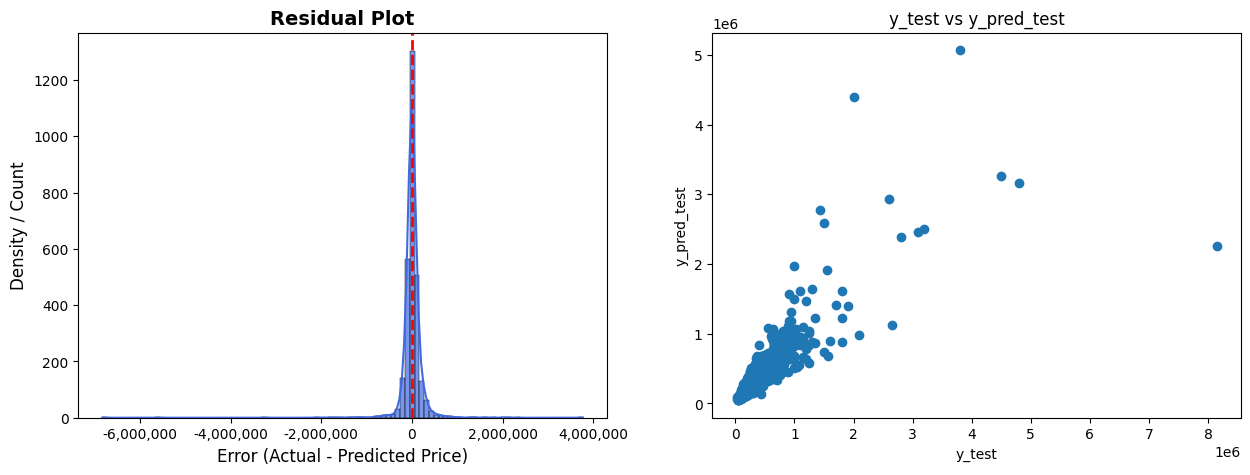

In [52]:
from sklearn.linear_model import LinearRegression
core_pipeline = Pipeline(steps=[
    ('aligner', FeatureAligner(num_fill=0, cat_fill='Unknown')),
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

final_lr_pipeline = TransformedTargetRegressor(
    regressor=core_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)
car_pred_model(final_lr_pipeline)

In [53]:
print(train_errors)

[[90101.9391113758, 85091.87435374229, 18673.68877457727, 165961.3153081775, -71889.53362459922, 47506.83861343539, -129749.51564247953, -120043.13914800563, -185112.2406114092, 150611.03216123, 89319.25922855485, 30599.01982599753, 56692.056944518, 134660.09575920185, 116333.90497444005, -314958.97548593255, 37830.31889592871, -179458.40647780214, -33284.36864296114, 1851.8090116160165, 70197.33811297698, 69645.45996708795, -65962.89346555911, -87211.25723644439, -198973.72565982013, 83960.68450390972, 65078.32618709351, -73888.89177937328, 57435.56792516797, -177608.45265961566, 306367.99803308526, -191063.03757465095, 101085.59921705874, 40523.71978835622, -20540.837555370468, -22058.04147957801, 86064.28348426806, 67349.94989474982, 19822.02788763563, 71266.3729810197, 100760.29229922174, -61293.04641810851, 60350.81108157453, 54233.44698497336, 44063.458136549656, -145874.98959811032, -590127.5713073458, -18455.28506146965, -10827.16925063869, -23763.12574515023, -148330.330712732

In [54]:
print(test_errors)

[[-188686.65631759953, 90049.43204408523, -55070.50760714221, -1268891.8356309766, -80959.50124813255, -133047.4590365411, 95661.82074337661, -99885.65112403955, -193380.19677488715, -29766.88146815964, 40001.350965758786, 188290.62938353978, -131066.23297745117, 138308.7014195032, -78212.5889805163, -110787.00336002896, 20469.328114960284, 102947.46426504408, -118249.56223918917, 108892.15012719715, 53682.70777230777, -5025.698963804127, 30205.449744888552, -54249.348040994955, 21595.934317828156, 25555.981053712894, 183478.20616858214, 25688.627990647918, 29975.02826323954, -32249.15139403558, 534400.9345846598, 52409.78680064692, 484291.9433119348, 25088.909409269458, -14481.080353915691, 111484.98380611406, 28292.49263941357, 246032.8681644007, 21318.270309841348, -43404.33598707244, 51227.57126888499, 25036.268775725563, 26336.762926998534, 129091.90473664191, -65737.03910392663, -17420.170363178768, -215463.31092924462, 104203.7443681203, 183383.96204132144, 6556.755649374914, 72

Train R2-score : 0.7911
 RMSE on Train  229076.71
Test R2-score : 0.6792
 RMSE on Test  306065.77
Train CV scores : [0.74819336 0.69842073 0.77623977 0.61947607 0.4029188 ]
Train CV mean : 0.65


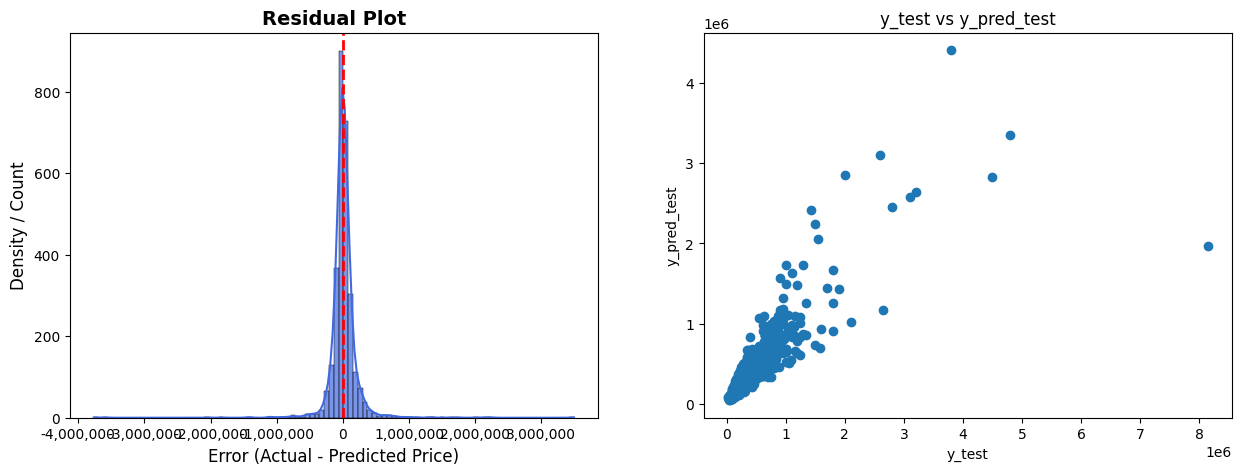

In [55]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import RandomizedSearchCV
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline

# Define the pipeline
core_pipeline = Pipeline(steps=[
    ('aligner', FeatureAligner(num_fill=0, cat_fill='Unknown')),
    ('preprocessor', preprocessor),
    ('regressor', Ridge())
])

final_ridge_pipeline = TransformedTargetRegressor(
    regressor=core_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

# Generate log-spaced alpha values
alpha = np.logspace(-3, 3, num=14)

param_distributions = {
    'regressor__regressor__alpha': alpha
}

# Creating RandomizedSearchCV with correct parameter mapping
rg_rs = RandomizedSearchCV(
    estimator=final_ridge_pipeline,
    param_distributions=param_distributions)

car_pred_model(rg_rs)

Train R2-score : 0.6362
 RMSE on Train  302317.14
Test R2-score : 0.5289
 RMSE on Test  370892.51
Train CV scores : [0.58790078 0.67679988 0.69458168 0.56071925 0.37908445]
Train CV mean : 0.58


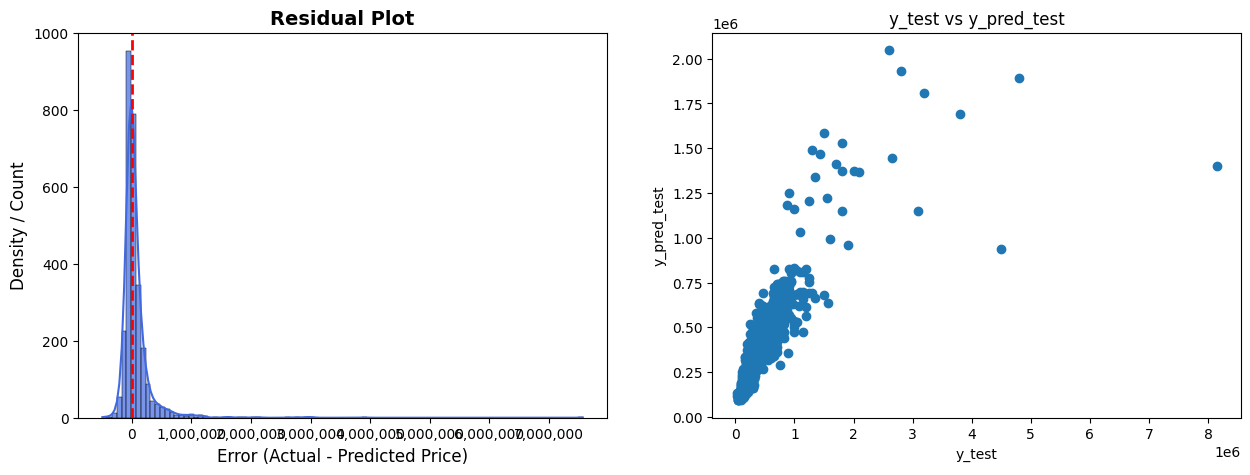

In [56]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline

# Define the pipeline
core_pipeline = Pipeline(steps=[
    ('aligner', FeatureAligner(num_fill=0, cat_fill='Unknown')),
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor())
])

final_RF_pipeline = TransformedTargetRegressor(
    regressor=core_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

# Number of trees in Random forest
n_estimators=list(range(500,1000,100))
# Maximum number of levels in a tree
max_depth=list(range(4,9,4))
# Minimum number of samples required to split an internal node
min_samples_split=list(range(4,9,2))
# Minimum number of samples required to be at a leaf node.
min_samples_leaf=[1,2,5,7]
# Number of fearures to be considered at each split
max_features=['sqrt', 'log2']


# Hyperparameters dict mapped correctly with nested step prefixes
param_grid = {
    "regressor__regressor__n_estimators": n_estimators,
    "regressor__regressor__max_depth": max_depth,
    "regressor__regressor__min_samples_split": min_samples_split,
    "regressor__regressor__min_samples_leaf": min_samples_leaf,
    "regressor__regressor__max_features": max_features
}

# Creating RandomizedSearchCV with the correct parameter routing
rf_rs = RandomizedSearchCV(
    estimator=final_RF_pipeline,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    random_state=42,
    n_jobs=-1
)

car_pred_model(rf_rs)

Train R2-score : 0.8368
 RMSE on Train  202469.52
Test R2-score : 0.749
 RMSE on Test  270713.8
Train CV scores : [0.75999886 0.78526407 0.85187668 0.70720863 0.50620008]
Train CV mean : 0.72


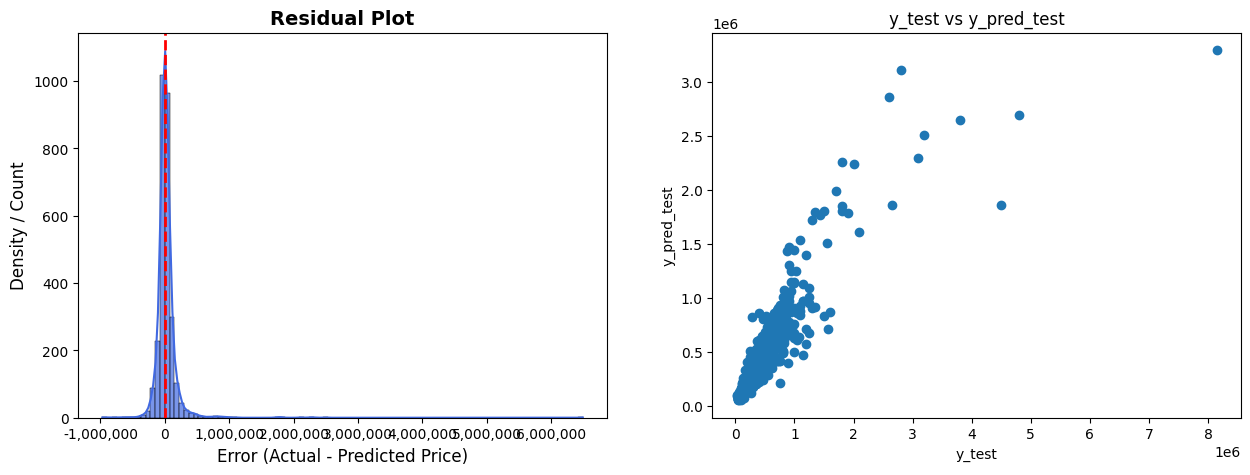

In [57]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
import numpy as np

# Define the base pipeline with XGBRegressor
core_pipeline = Pipeline(steps=[
    ('aligner', FeatureAligner(num_fill=0, cat_fill='Unknown')),
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(random_state=42))
])

# Wrap with TransformedTargetRegressor
final_XG_pipeline = TransformedTargetRegressor(
    regressor=core_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

# Define the hyperparameter search space for XGBRegressor
# Note the double underscore prefixing for nested estimator routing
xg_param_grid = {
    'regressor__regressor__n_estimators': [100, 300, 500, 700, 1000],
    'regressor__regressor__max_depth': [3, 4, 6, 8],
    'regressor__regressor__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'regressor__regressor__subsample': [0.6, 0.8, 1.0],
    'regressor__regressor__colsample_bytree': [0.6, 0.8, 1.0]
}

# Create RandomizedSearchCV
xg_rs = RandomizedSearchCV(
    estimator=final_XG_pipeline,
    param_distributions=xg_param_grid,
    n_iter=10,
    cv=3,
    random_state=42,
    n_jobs=-1
)

# Execute search and evaluate using your custom helper function
car_pred_model(xg_rs)

Train R2-score : 0.917
 RMSE on Train  144417.93
Test R2-score : 0.7676
 RMSE on Test  260485.17
Train CV scores : [0.75968801 0.7369313  0.8287903  0.26458767 0.59293418]
Train CV mean : 0.64


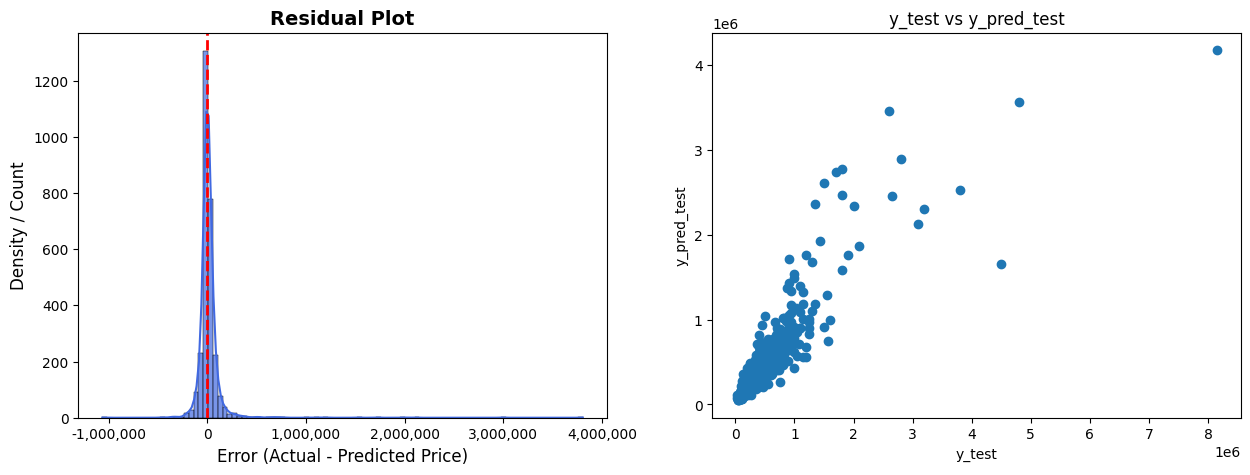

In [58]:
from typing import final
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV
core_pipeline = Pipeline(steps=[
    ('aligner', FeatureAligner(num_fill=0, cat_fill='Unknown')),
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor())
])
final_gb_pipeline = TransformedTargetRegressor(
    regressor=core_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)
# Rate at which correcting is being made
learning_rate = [0.001, 0.01, 0.1, 0.2]
# Number of trees in Gradient boosting
n_estimators=list(range(500,1000,100))
# Maximum number of levels in a tree
max_depth=list(range(4,9,4))
# Minimum number of samples required to split an internal node
min_samples_split=list(range(4,9,2))
# Minimum number of samples required to be at a leaf node.
min_samples_leaf=[1,2,5,7]
# Number of fearures to be considered at each split
max_features=['log2','sqrt']

# Hyperparameters dict
param_grid = {"regressor__regressor__learning_rate":learning_rate,
              "regressor__regressor__n_estimators":n_estimators,
              "regressor__regressor__max_depth":max_depth,
              "regressor__regressor__min_samples_split":min_samples_split,
              "regressor__regressor__min_samples_leaf":min_samples_leaf,
              "regressor__regressor__max_features":max_features}

gb_rs = RandomizedSearchCV(estimator = final_gb_pipeline, param_distributions = param_grid)
car_pred_model(gb_rs)

⏳ Initializing SHAP Explainer (Opening the Black Box)...


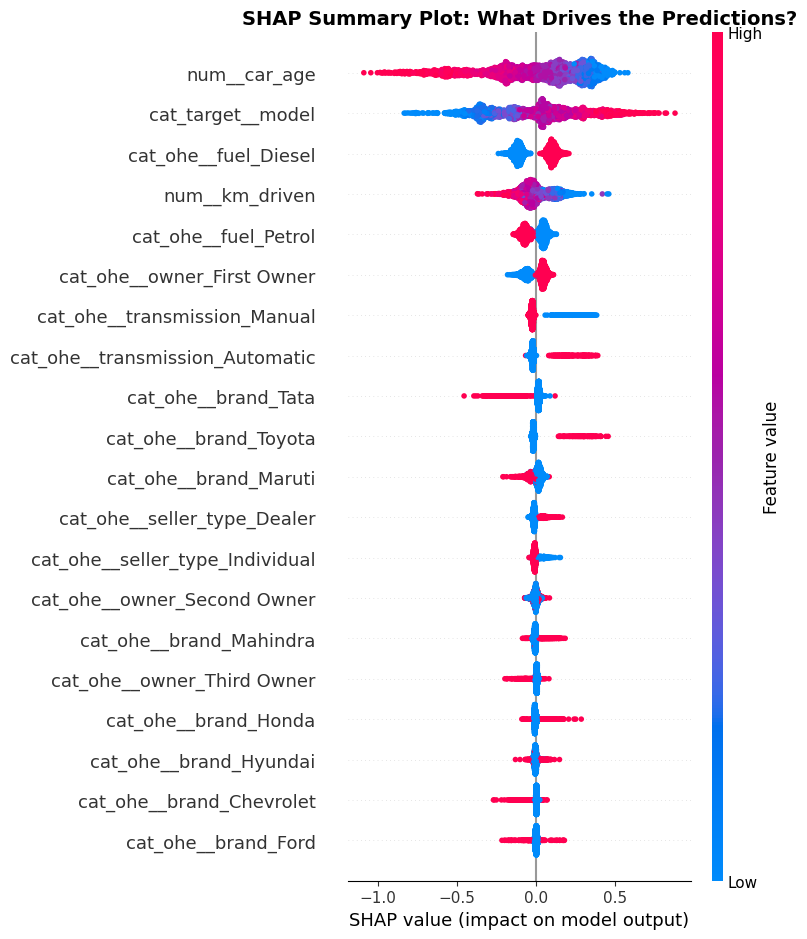

In [59]:

!pip install -q shap

import shap
import pandas as pd
import matplotlib.pyplot as plt
best_pipeline = gb_rs.best_estimator_.regressor_

gb_model = best_pipeline.named_steps['regressor']

X_train_transformed = best_pipeline[:-1].transform(x_train)


try:
    feature_names = best_pipeline[:-1].get_feature_names_out()
except AttributeError:

    feature_names = best_pipeline.named_steps['preprocessor'].get_feature_names_out()

X_train_shap = pd.DataFrame(X_train_transformed, columns=feature_names)

print("⏳ Initializing SHAP Explainer (Opening the Black Box)...")

explainer = shap.TreeExplainer(gb_model)


shap_values = explainer.shap_values(X_train_shap)


plt.figure(figsize=(12, 8))
plt.title("SHAP Summary Plot: What Drives the Predictions?", fontsize=14, fontweight='bold')


shap.summary_plot(shap_values, X_train_shap, show=False)

plt.tight_layout()
plt.show()

In [60]:
goat_model=gb_rs.best_estimator_
print(goat_model)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('aligner',
                                                      FeatureAligner()),
                                                     ('preprocessor',
                                                      ColumnTransformer(remainder='passthrough',
                                                                        transformers=[('num',
                                                                                       Pipeline(steps=[('imputer',
                                                                                                        SimpleImputer(strategy='median')),
                                                                                                       ('yeo_johnson',
                                                                                                        PowerTransformer(standardize=False)),
       

In [61]:
 import joblib
from pathlib import Path

project_dir = Path('.')

models_dir = project_dir / 'models'


models_dir.mkdir(exist_ok=True)


model_path = models_dir / 'car_price_model.pkl'
joblib.dump(goat_model, model_path)

['models/car_price_model.pkl']

In [62]:
from utils import validate_car_data

In [63]:
!pip install -q streamlit
!npm install localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏
up to date, audited 23 packages in 2s
⠏
⠏3 packages are looking for funding
⠏  run `npm fund` for details
⠏
2 high severity vulnerabilities

To address all issues (including breaking changes), run:
  npm audit fix --force

Run `npm audit` for details.
⠋

In [ ]:
get_ipython().system_raw('streamlit run /content/drive/MyDrive/car_price_prediction/car_app.py &')
!wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x cloudflared-linux-amd64

!./cloudflared-linux-amd64 tunnel --url http://localhost:8501

2026-10-18T20:39:01Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-18T20:39:01Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-18T20:39:04Z INF +--------------------------------------------------------------------------------------------+
2026-10-18T20:39:04Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-18T20:39:04Z INF |  https://thunder-erik-concrete-transit.trycloudflare.c

In [ ]:
pip freeze > requirements.txt

In [69]:
clean_car_df.head(10)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,brand,model,car_age
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner,Maruti,800,19
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner,Maruti,Wagon-R,19
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner,Hyundai,Verna,14
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner,Datsun,RediGO,9
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner,Honda,Amaze,12
5,Maruti Alto LX BSIII,2007,140000,125000,Petrol,Individual,Manual,First Owner,Maruti,Alto,19
6,Hyundai Xcent 1.2 Kappa S,2016,550000,25000,Petrol,Individual,Manual,First Owner,Hyundai,Xcent,10
7,Tata Indigo Grand Petrol,2014,240000,60000,Petrol,Individual,Manual,Second Owner,Tata,Indigo,12
8,Hyundai Creta 1.6 VTVT S,2015,850000,25000,Petrol,Individual,Manual,First Owner,Hyundai,Creta,11
9,Maruti Celerio Green VXI,2017,365000,78000,Gas,Individual,Manual,First Owner,Maruti,Celerio,9
